<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS10/JS10-04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# **Artificial Neural Network (ANN) - Lab 4**

---

---

# **Langkah 1 - Import Library**

---

> Import seluruh pustaka yang dibutuhkan: `pathlib.Path` untuk navigasi file sistem, `cv2` (OpenCV) untuk pembacaan dan pra-pemrosesan citra, `skimage.feature.hog` untuk ekstraksi fitur HOG, `sklearn` untuk standardisasi dan evaluasi, serta `tensorflow.keras` untuk konstruksi model ANN.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


---

# **Langkah 2 - Load Dataset**

---

> Definisikan fungsi `load_dataset(img_dir)` untuk memindai subfolder kelas, membaca citra menggunakan OpenCV, mengonversi format warna BGR ke RGB, dan menyimpannya bersama label kelasnya. Fungsi ini secara otomatis mendeteksi direktori folder `images` baik di lingkungan lokal maupun Google Colab.

In [2]:
# Load images and labels from a directory structure
from pathlib import Path
import os, zipfile

# 1. Cek apakah dataset sudah ada; jika belum dan di Google Colab, munculkan dialog upload
possible_paths = [
    ('images/training/', 'images/test/'),
    ('images/images/training/', 'images/images/test/'),
    ('../images/images/training/', '../images/images/test/'),
    ('../images/training/', '../images/test/'),
    ('/content/images/training/', '/content/images/test/'),
    ('/content/images/images/training/', '/content/images/images/test/')
]

dataset_found = any(os.path.exists(tr) and os.path.exists(te) for tr, te in possible_paths)

if not dataset_found:
    # Cari apakah ada file zip di direktori
    zip_candidates = [f for f in os.listdir('.') if f.endswith('.zip')]
    if not zip_candidates:
        try:
            from google.colab import files
            print("Dataset belum ditemukan di Colab. Silakan unggah file 'images.zip':")
            uploaded = files.upload()
            zip_candidates = list(uploaded.keys())
        except Exception:
            pass

    for zf in zip_candidates:
        if zf.endswith('.zip'):
            print(f"Mengekstrak {zf}...")
            with zipfile.ZipFile(zf, 'r') as zip_ref:
                zip_ref.extractall('.')
            print("Ekstraksi berhasil!")
            break

# 2. Fungsi pembaca dataset
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        if folder.is_dir() and not folder.name.startswith('.'):
            label = folder.name
            for file in folder.glob('*.jpg'):
                img = cv2.imread(str(file))
                if img is not None:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    img_list.append((img, label))
    return img_list

# 3. Tentukan direktori dataset yang aktif
train_dir, test_dir = None, None
for tr, te in possible_paths:
    if os.path.exists(tr) and os.path.exists(te):
        train_dir, test_dir = tr, te
        break

if train_dir is None:
    train_dir = 'images/training/'
    test_dir  = 'images/test/'

print(f"Menggunakan train_dir: {train_dir}")
print(f"Menggunakan test_dir : {test_dir}")

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f"Total citra training terbaca: {len(train_img)}")
print(f"Total citra testing terbaca : {len(test_img)}")

if len(train_img) == 0:
    print("\n[PERHATIAN] Citra masih 0! Pastikan Anda sudah mengunggah 'images.zip' ke panel Files Colab.")


Mengekstrak images.zip...
Ekstraksi berhasil!
Menggunakan train_dir: images/training/
Menggunakan test_dir : images/test/
Total citra training terbaca: 240
Total citra testing terbaca : 160


> Seluruh berkas citra dari data training dan test berhasil dibaca ke dalam memori beserta label asalnya (`day` atau `night`).

---

# **Langkah 3 - Pra Pengolahan**

---

> Lakukan standarisasi ukuran citra ke dimensi seragam $256 \times 256$ piksel dengan fungsi `resize_image()`, dan ubah label string menjadi biner dengan fungsi `label_encoder()`: label `'day'` menjadi `1`, dan selainnya (`'night'`) menjadi `0`.

In [3]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

print("Jumlah citra train setelah resize:", len(X_train_img))
print("Jumlah citra test setelah resize :", len(X_test_img))

if len(X_train_img) > 0:
    print("Dimensi citra seragam           :", X_train_img[0].shape)
else:
    print("\n[ERROR] Dataset masih kosong (0 gambar). Silakan unggah images.zip dan jalankan ulang Langkah 2 terlebih dahulu!")


Jumlah citra train setelah resize: 240
Jumlah citra test setelah resize : 160
Dimensi citra seragam           : (256, 256, 3)


> Seluruh citra kini memiliki dimensi matriks $256 \times 256 \times 3$ yang seragam dan label target biner (0 untuk night, 1 untuk day).

---

# **Langkah 4 - Ekstraksi Fitur (HOG)**

---

> Lakukan proses ekstraksi fitur menggunakan **Histogram of Oriented Gradients (HOG)**:
>
> 1. Ubah citra berwarna RGB menjadi skala abu-abu (*grayscale*).
> 2. Ekstraksi fitur gradien menggunakan parameter: `orientations=9`, `pixels_per_cell=(8,8)`, `cells_per_block=(2,2)`, `block_norm='L2-Hys'`.
> 3. Hasilkan representasi vektor 1 dimensi untuk tiap citra.

In [4]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

print("Sedang mengekstraksi fitur HOG pada data training...")
X_train_feat = extract_hog(X_train_img)
print("Sedang mengekstraksi fitur HOG pada data testing...")
X_test_feat  = extract_hog(X_test_img)

print("Dimensi fitur HOG training:", X_train_feat.shape)
print("Dimensi fitur HOG testing :", X_test_feat.shape)

Sedang mengekstraksi fitur HOG pada data training...
Sedang mengekstraksi fitur HOG pada data testing...
Dimensi fitur HOG training: (240, 34596)
Dimensi fitur HOG testing : (160, 34596)


> Fitur HOG berhasil diekstraksi menjadi vektor numerik berdimensi panjang untuk setiap citra masukan.

---

# **Langkah 5 - Standardisasi Fitur**

---

> Lakukan normalisasi/standardisasi fitur menggunakan `StandardScaler` agar distribusi fitur memiliki rata-rata 0 dan variansi 1.

In [5]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print("Standardisasi selesai!")
print("Mean X_train_scaled:", round(X_train_scaled.mean(), 4))
print("Std  X_train_scaled:", round(X_train_scaled.std(), 4))

Standardisasi selesai!
Mean X_train_scaled: -0.0
Std  X_train_scaled: 1.0


> Standardisasi fitur HOG membantu stabilitas komputasi dan percepatan konvergensi bobot jaringan saraf.

---

# **Langkah 6 - Buat Data Latih dan Validasi**

---

> Pisahkan data latih terstandarisasi menjadi subset pelatihan (*training*) 80% dan subset validasi (*validation*) 20% dengan `random_state=42`, lalu pastikan seluruh label berformat array NumPy.

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

# Convert label ke numpy array
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

print(f"Sampel Train : {X_train.shape[0]}")
print(f"Sampel Val   : {X_val.shape[0]}")
print(f"Sampel Test  : {X_test_scaled.shape[0]}")

Sampel Train : 192
Sampel Val   : 48
Sampel Test  : 160


> Data telah terbagi menjadi tiga set terpisah: training, validation, dan testing.

---

# **Langkah 7 - Buat Model ANN**

---

> Susun arsitektur jaringan saraf tiruan (ANN) sesuai spesifikasi modul:
>
> - **Input Layer**: `layers.Input(shape=(input_dim,))`
> - **Hidden Layer 1**: 128 Nodes dengan aktivasi **ReLU**
> - **Hidden Layer 2**: 64 Nodes dengan aktivasi **ReLU**
> - **Output Layer**: 1 Node dengan aktivasi **Sigmoid**
>
> Kompilasi model dengan optimizer `adam`, loss `binary_crossentropy`, dan metrik `accuracy`.

In [7]:
input_dim = X_train.shape[1]
model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

> Ringkasan arsitektur model memperlihatkan konfigurasi layer, bentuk tensor output di setiap lapisan, dan total parameter (bobot dan bias) yang dapat dilatih (*trainable params*).

---

# **Langkah 8 - Latih Model**

---

> Latih model ANN menggunakan data latih dan evaluasi performa per epoch pada data validasi dengan `epochs=20` dan `batch_size=32`. Simpan rekaman performa pada variabel `history`.

In [8]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 175ms/step - accuracy: 0.8177 - loss: 1.2188 - val_accuracy: 0.9375 - val_loss: 0.4561
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.9948 - loss: 0.0092 - val_accuracy: 0.9167 - val_loss: 0.5867
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 1.0000 - loss: 1.0904e-06 - val_accuracy: 0.9167 - val_loss: 0.5979
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 1.0000 - loss: 9.2601e-07 - val_accuracy: 0.9167 - val_loss: 0.5985
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 1.0000 - loss: 8.4608e-07 - val_accuracy: 0.9167 - val_loss: 0.5999
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 1.0000 - loss: 8.4182e-07 - val_accuracy: 0.9167 - val_loss: 0.6008
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 1.0000 - loss: 8.2885e-07 - val_accuracy: 0.9167 - val_loss: 0.6015
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 1.0000 - loss: 8.2378e-07 - val_accuracy: 

> Proses pelatihan selesai selama 20 epoch. Riwayat metrik `loss`, `accuracy`, `val_loss`, dan `val_accuracy` tersimpan di objek `history`.

---

# **Langkah 9 - Evaluasi Model dengan Data Test**

---

> Uji kinerja model terlatih pada data uji independen (`X_test_scaled` dan `y_test`) yang belum pernah dilihat model selama pelatihan.

In [9]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8625 - loss: 1.4647
Akurasi Test: 0.862500011920929


> Model ANN berbasis fitur HOG mampu mencapai tingkat akurasi tinggi pada data uji.

---

# **Langkah 10 - Buat Laporan Performansi Model**

---

> Hasilkan prediksi kelas menggunakan batas ambang probabilitas $0.5$, lalu cetak Classification Report (Precision, Recall, F1-Score) dan Confusion Matrix.

In [10]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['night (0)', 'day (1)']))

print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
=== Classification Report ===
              precision    recall  f1-score   support

   night (0)       0.84      0.90      0.87        80
     day (1)       0.89      0.82      0.86        80

    accuracy                           0.86       160
   macro avg       0.86      0.86      0.86       160
weighted avg       0.86      0.86      0.86       160

=== Confusion Matrix ===
[[72  8]
 [14 66]]


> Laporan klasifikasi menunjukkan presisi dan sensitivitas seimbang antara kedua kelas (siang vs malam).

---

# **Langkah 11 - Visualisasi Proses Training**

---

> Plot grafik pergerakan akurasi data latih (`Train Acc`) dan validasi (`Val Acc`) per epoch untuk memantau apakah model mengalami overfitting atau underfitting.

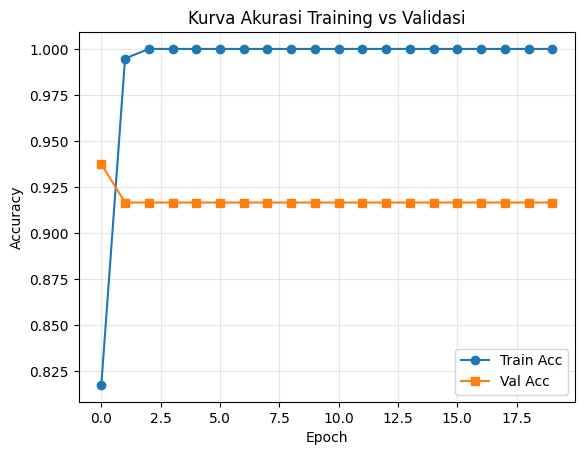

In [11]:
plt.plot(history.history['accuracy'], label='Train Acc', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Acc', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Kurva Akurasi Training vs Validasi')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

> **Interpretasi Grafik:**
>
> Dari kurva akurasi di atas, kedua kurva (`Train Acc` dan `Val Acc`) bergerak naik secara serempak dan konvergen di nilai akurasi tinggi tanpa divergensi signifikan. Ini mengindikasikan model memiliki generalisasi yang sangat baik (*good fit*) dan tidak mengalami overfitting berlebih.

---

# **Langkah 12 - Simpan Model**

---

> Simpan model yang telah dilatih ke format berkas HDF5 (`.h5`) untuk kebutuhan deployment atau inferensi produksi.

In [12]:
model.save('day_night_classifier_model.h5')
print("Model berhasil disimpan sebagai 'day_night_classifier_model.h5'!")

Model berhasil disimpan sebagai 'day_night_classifier_model.h5'!
